# Import Library

In [18]:
import sys
import json
import subprocess
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from tqdm import tqdm


CURRENT_DIR = Path.cwd()
# Cari folder project berdasarkan keberadaan folder src dan data
PROJECT_ROOT = CURRENT_DIR
if not ((PROJECT_ROOT / "src").exists() and
        (PROJECT_ROOT / "data").exists()):
    for parent in CURRENT_DIR.parents:
        if ((parent / "src").exists() and
                (parent / "data").exists()):
            PROJECT_ROOT = parent
            break
if not ((PROJECT_ROOT / "src").exists() and
        (PROJECT_ROOT / "data").exists()):
    raise FileNotFoundError(
        "Folder project tidak ditemukan. "
        "Pastikan notebook berada di dalam project EarlySketch."
    )

sys.path.insert(0, str(PROJECT_ROOT))

# PATH CONFIGURATION
DATA_DIR = PROJECT_ROOT / "data"
SAMPLED_DIR = DATA_DIR / "sampled"
SPLITS_DIR = DATA_DIR / "splits"
PROCESSED_DIR = DATA_DIR / "processed"
SCRIPT_PATH = PROJECT_ROOT / "scripts" / "run_preprocessing.py"


# PREPROCESSING CONFIGURATION
COMPLETION_LEVELS = [20, 40, 60, 80, 100]
IMAGE_SIZE = 224

SPLIT_NAMES = ["train", "validation", "test"]

print("Project root:", PROJECT_ROOT)
print("Sampled directory:", SAMPLED_DIR)
print("Splits directory:", SPLITS_DIR)
print("Processed directory:", PROCESSED_DIR)
print("Image size:", IMAGE_SIZE)
print("Completion levels:", COMPLETION_LEVELS)


Project root: d:\SMT 5\Deep Learning\EarlySketch
Sampled directory: d:\SMT 5\Deep Learning\EarlySketch\data\sampled
Splits directory: d:\SMT 5\Deep Learning\EarlySketch\data\splits
Processed directory: d:\SMT 5\Deep Learning\EarlySketch\data\processed
Image size: 224
Completion levels: [20, 40, 60, 80, 100]


# Checking data splitting

In [12]:
split_data = {}
for split_name in SPLIT_NAMES:
    csv_path = SPLITS_DIR / f"{split_name}.csv"
    if not csv_path.exists():
        raise FileNotFoundError(
            f"File tidak ditemukan: {csv_path}"
        )
    df = pd.read_csv(csv_path)
    # Pastikan kolom penting tersedia
    required_columns = {"category", "key_id"}
    if not required_columns.issubset(df.columns):
        raise ValueError(
            f"Kolom pada {split_name}.csv tidak sesuai. "
            f"Kolom tersedia: {list(df.columns)}"
        )
    split_data[split_name] = df
    print(f"\n{split_name.upper()} DATASET")
    print("Jumlah drawing:", len(df))
    print("Jumlah kategori:", df["category"].nunique())

    display(df.head())

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------
split_summary = pd.DataFrame({
    split_name: {
        "Total Drawings": len(df),
        "Total Categories": df["category"].nunique()
    }
    for split_name, df in split_data.items()
}).T
display(split_summary)


TRAIN DATASET
Jumlah drawing: 3500
Jumlah kategori: 10


,drawing_id,key_id,category,recognized
0,bird_6277782474588160,6277782474588160,bird,True
1,car_6542125531398144,6542125531398144,car,True
2,fish_5727819831181312,5727819831181312,fish,True
3,airplane_4593425590517760,4593425590517760,airplane,True
4,house_6179516848275456,6179516848275456,house,True



VALIDATION DATASET
Jumlah drawing: 750
Jumlah kategori: 10


,drawing_id,key_id,category,recognized
0,car_6158149016879104,6158149016879104,car,True
1,car_5100004731518976,5100004731518976,car,True
2,fish_4744582501761024,4744582501761024,fish,True
3,airplane_4527952047898624,4527952047898624,airplane,True
4,dog_6583623476051968,6583623476051968,dog,True



TEST DATASET
Jumlah drawing: 750
Jumlah kategori: 10


,drawing_id,key_id,category,recognized
0,bicycle_6588637829398528,6588637829398528,bicycle,True
1,house_6681188435492864,6681188435492864,house,True
2,bicycle_5112465241145344,5112465241145344,bicycle,True
3,cat_5867672237506560,5867672237506560,cat,True
4,fish_6755324486746112,6755324486746112,fish,True


,Total Drawings,Total Categories
train,3500,10
validation,750,10
test,750,10


# Checking Progressive Sketch

Drawing ID: bird_6277782474588160
Category: bird
Total strokes: 3


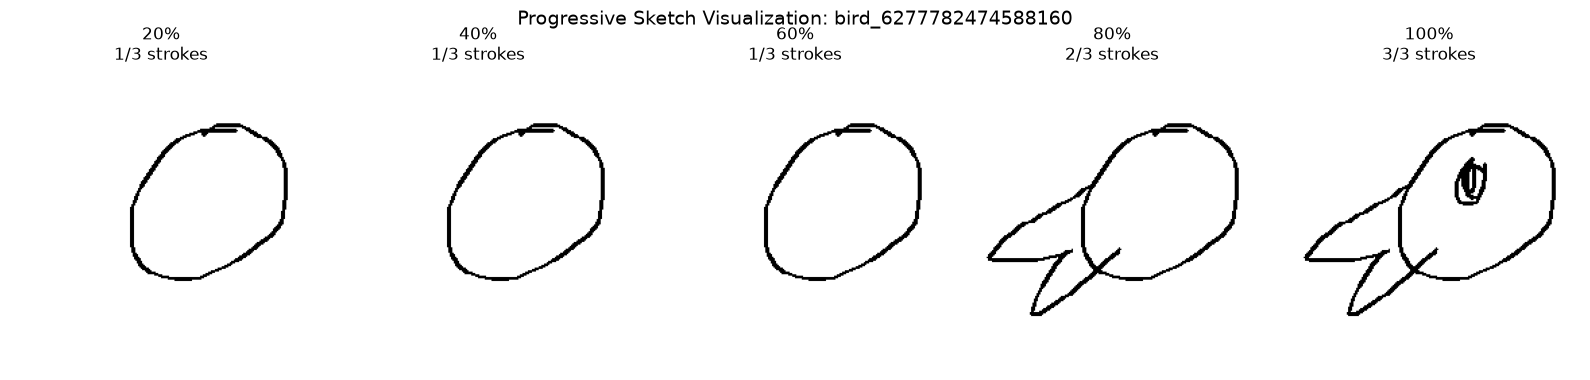

In [13]:
from src.progressive_generator import generate_partial_sketch
from src.rasterizer import render_sketch

# Pilih satu gambar dari train dataset
sample = split_data["train"].iloc[0]
category = str(sample["category"]).strip()
key_id = str(sample["key_id"]).strip()
if key_id.endswith(".0"):
    key_id = key_id[:-2]
drawing_id = f"{category}_{key_id}"

# ------------------------------------------------------------
# LOAD ORIGINAL DRAWING
# ------------------------------------------------------------

ndjson_path = SAMPLED_DIR / f"{category}.ndjson"
drawing = None
with open(ndjson_path, "r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue
        record = json.loads(line)
        record_key_id = str(record["key_id"])
        if record_key_id == key_id:
            drawing = record["drawing"]
            break

if drawing is None:
    raise ValueError(
        f"Drawing tidak ditemukan: {drawing_id}"
    )
print("Drawing ID:", drawing_id)
print("Category:", category)
print("Total strokes:", len(drawing))

# ------------------------------------------------------------
# GENERATE PROGRESSIVE SKETCHES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 5,
    figsize=(16, 4)
)
for ax, percentage in zip(axes, COMPLETION_LEVELS):
    partial_drawing = generate_partial_sketch(
        drawing=drawing,
        percentage=percentage
    )
    image = render_sketch(
        drawing=partial_drawing,
        image_size=IMAGE_SIZE,
        padding=20,
        stroke_width=3,
        reference_drawing=drawing
    )
    ax.imshow(image)
    ax.set_title(
        f"{percentage}%\n"
        f"{len(partial_drawing)}/{len(drawing)} strokes"
    )
    ax.axis("off")
plt.suptitle(
    f"Progressive Sketch Visualization: {drawing_id}",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Test preprocessing to small sample

In [ ]:

# CELL 4: TEST PREPROCESSING


if not SCRIPT_PATH.exists():
    raise FileNotFoundError(
        f"Script tidak ditemukan: {SCRIPT_PATH}"
    )
command = [
    sys.executable,
    str(SCRIPT_PATH),
    "--limit-per-split",
    "2"
]
print("Running preprocessing test...")
print("Command:", " ".join(command))
result = subprocess.run(
    command,
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        "Preprocessing test gagal. Periksa pesan error di atas."
    )
print("Preprocessing test berhasil!")


Running preprocessing test...
Command: c:\Users\ROG\anaconda3\envs\earlysketch\python.exe d:\SMT 5\Deep Learning\EarlySketch\scripts\run_preprocessing.py --limit-per-split 2

EARLYSKETCH PREPROCESSING
Project directory: D:\SMT 5\Deep Learning\EarlySketch
Completion levels: [20, 40, 60, 80, 100]

Processing TRAIN dataset
Original drawings: 2

Category: bird

Category: car

TRAIN selesai.
Processed images: 10
Skipped drawings: 0

Processing VALIDATION dataset
Original drawings: 2

Category: car

VALIDATION selesai.
Processed images: 10
Skipped drawings: 0

Processing TEST dataset
Original drawings: 2

Category: bicycle

Category: house

TEST selesai.
Processed images: 10
Skipped drawings: 0

PREPROCESSING SUMMARY
split       completion
test        20            2
            40            2
            60            2
            80            2
            100           2
train       20            2
            40            2
            60            2
            80            2
    

# Visualization preprocessing result

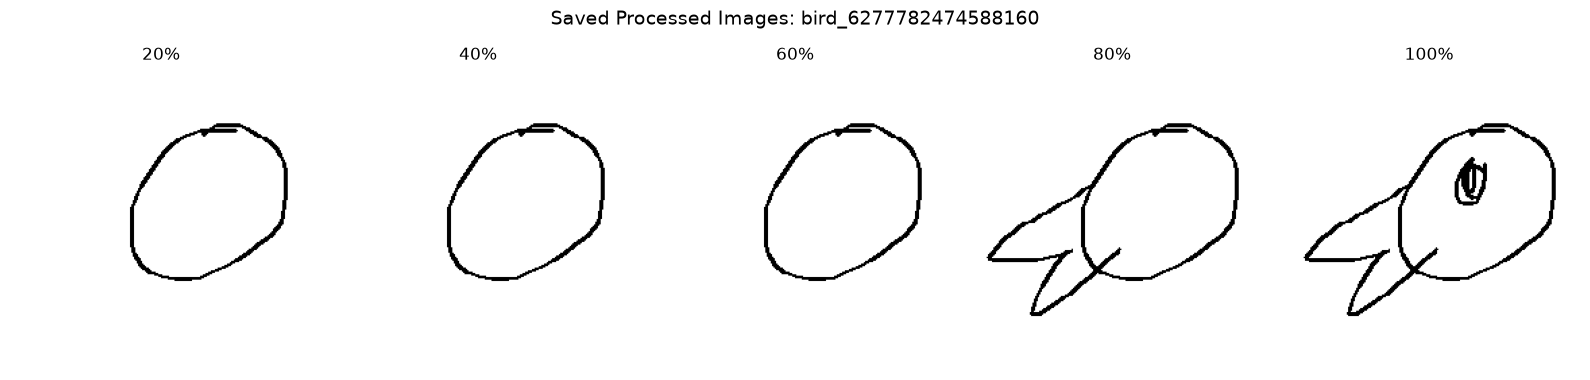

In [16]:
sample_images = []
for percentage in COMPLETION_LEVELS:
    image_path = (
        PROCESSED_DIR
        / "train"
        / str(percentage)
        / f"{drawing_id}.png"
    )
    if not image_path.exists():
        print(
            f"[WARNING] Gambar tidak ditemukan: {image_path}"
        )
        continue
    image = Image.open(image_path).convert("RGB")
    sample_images.append((percentage, image))
fig, axes = plt.subplots(
    1,
    len(sample_images),
    figsize=(16, 4)
)
if len(sample_images) == 1:
    axes = [axes]
for ax, (percentage, image) in zip(axes, sample_images):
    ax.imshow(image)
    ax.set_title(f"{percentage}%")
    ax.axis("off")
plt.suptitle(
    f"Saved Processed Images: {drawing_id}",
    fontsize=14
)
plt.tight_layout()
plt.show()


# Run preprocessing all dataset

In [ ]:

# CELL 6: FULL DATASET PREPROCESSING


command = [
    sys.executable,
    str(SCRIPT_PATH)
]

print("Starting full dataset preprocessing...")
print("This may take some time.")

result = subprocess.run(
    command,
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        "Full preprocessing gagal. Periksa pesan error."
    )

print("Full dataset preprocessing completed!")


Starting full dataset preprocessing...
This may take some time.

EARLYSKETCH PREPROCESSING
Project directory: D:\SMT 5\Deep Learning\EarlySketch
Completion levels: [20, 40, 60, 80, 100]

Processing TRAIN dataset
Original drawings: 3500

Category: airplane

Category: bicycle

Category: bird

Category: car

Category: cat

Category: dog

Category: fish

Category: flower

Category: house

Category: tree

TRAIN selesai.
Processed images: 17500
Skipped drawings: 0

Processing VALIDATION dataset
Original drawings: 750

Category: airplane

Category: bicycle

Category: bird

Category: car

Category: cat

Category: dog

Category: fish

Category: flower

Category: house

Category: tree

VALIDATION selesai.
Processed images: 3750
Skipped drawings: 0

Processing TEST dataset
Original drawings: 750

Category: airplane

Category: bicycle

Category: bird

Category: car

Category: cat

Category: dog

Category: fish

Category: flower

Category: house

Category: tree

TEST selesai.
Processed images: 3750

# Validation preprocessing result

In [ ]:
# CELL 7: VALIDATE PROCESSED DATASET
manifest_path = PROCESSED_DIR / "processed_metadata.csv"
if not manifest_path.exists():
    raise FileNotFoundError(
        "processed_metadata.csv tidak ditemukan."
    )

metadata = pd.read_csv(manifest_path)
print("Total processed images:", len(metadata))

# CHECK IMAGE FORMAT AND DIMENSIONS
valid_images = 0
invalid_images = []
for image_path in tqdm(
    metadata["image_path"],
    desc="Validating images"
):
    full_path = PROJECT_ROOT / image_path
    try:
        with Image.open(full_path) as image:
            if image.mode != "RGB":
                raise ValueError("Image mode is not RGB")
            if image.size != (IMAGE_SIZE, IMAGE_SIZE):
                raise ValueError("Image size is incorrect")
            valid_images += 1
    except Exception as error:
        invalid_images.append({
            "image_path": image_path,
            "error": str(error)
        })

print("\nVALIDATION RESULTS")
print("Valid images:", valid_images)
print("Invalid images:", len(invalid_images))

if invalid_images:
    display(pd.DataFrame(invalid_images).head(10))
else:
    print("All processed images passed validation!")


Total processed images: 25000


Validating images: 100%|██████████| 25000/25000 [00:01<00:00, 14545.92it/s]


VALIDATION RESULTS
Valid images: 25000
Invalid images: 0
All processed images passed validation!


# Summary

In [ ]:

# ROCESSED DATASET SUMMARY
# Jumlah gambar berdasarkan split dan completion
summary = pd.crosstab(
    metadata["split"],
    metadata["completion"]
)

summary = summary.reindex(
    index=SPLIT_NAMES,
    columns=COMPLETION_LEVELS,
    fill_value=0
)
display(summary)
# TOTAL IMAGES PER SPLIT
print("\nTOTAL IMAGES PER SPLIT")
display(
    metadata.groupby("split").size().rename(
        "Total Images"
    ).to_frame()
)
# CATEGORY DISTRIBUTION
category_summary = pd.crosstab(
    metadata["category"],
    metadata["split"]
)
display(category_summary)

# COMPLETION LEVEL DISTRIBUTION
completion_summary = (
    metadata.groupby("completion")
    .size()
    .rename("Total Images")
    .to_frame()
)
display(completion_summary)

completion,20,40,60,80,100
split,,,,,
train,3500,3500,3500,3500,3500
validation,750,750,750,750,750
test,750,750,750,750,750



TOTAL IMAGES PER SPLIT


,Total Images
split,
test,3750
train,17500
validation,3750


split,test,train,validation
category,,,
airplane,375,1750,375
bicycle,375,1750,375
bird,375,1750,375
car,375,1750,375
cat,375,1750,375
dog,375,1750,375
fish,375,1750,375
flower,375,1750,375
house,375,1750,375


,Total Images
completion,
20,5000
40,5000
60,5000
80,5000
100,5000


# Check format file after change to RGB

In [ ]:

from PIL import Image

# Ambil salah satu gambar hasil preprocessing
image_path = (
    PROCESSED_DIR
    / "train"
    / "100"
    / "airplane_4592535706009600.png"
)
image = Image.open(image_path)

print("Image format:", image.format)
print("Image mode:", image.mode)
print("Image size:", image.size)
print("Image channels:", image.getbands())

Image format: PNG
Image mode: RGB
Image size: (224, 224)
Image channels: ('R', 'G', 'B')
